# Week 2 Mini Project — Sales Data Analyzer

## Objective

The objective of this project is to build a Sales Data Analyzer using Python and Pandas.

The project will:
- Load sales data from a CSV file
- Inspect and understand the dataset
- Clean the data
- Handle missing and incorrect values
- Perform sales analysis
- Calculate important business KPIs
- Identify the best-performing product and region
- Analyze monthly sales performance
- Create visualizations to understand sales trends

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
df = pd.read_csv("sales.csv")
df.head()

,Date,Product,Category,Quantity,Price,Revenue,Region
596,2025-12-30,Water Bottle,Accessories,7.0,266.39,1864.73,South
597,2025-12-30,Headphones,Electronics,5.0,3203.36,16016.80,West
598,2025-12-31,Backpack,Accessories,2.0,1284.61,2569.22,South
599,2025-12-31,Notebook Set,Stationery,2.0,189.78,379.56,South
600,2025-10-22,Notebook Set,Stationery,10.0,221.33,2213.30,West


In [31]:
df.tail()

,Date,Product,Category,Quantity,Price,Revenue,Region
596,2025-12-30,Water Bottle,Accessories,7.0,266.39,1864.73,South
597,2025-12-30,Headphones,Electronics,5.0,3203.36,16016.80,West
598,2025-12-31,Backpack,Accessories,2.0,1284.61,2569.22,South
599,2025-12-31,Notebook Set,Stationery,2.0,189.78,379.56,South
600,2025-10-22,Notebook Set,Stationery,10.0,221.33,2213.30,West


In [32]:
df.shape

(601, 7)

In [33]:
df.columns

Index(['Date', 'Product', 'Category', 'Quantity', 'Price', 'Revenue',
       'Region'],
      dtype='str')

In [34]:
df.dtypes

Date            str
Product         str
Category        str
Quantity    float64
Price       float64
Revenue     float64
Region          str
dtype: object

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      601 non-null    str    
 1   Product   601 non-null    str    
 2   Category  601 non-null    str    
 3   Quantity  598 non-null    float64
 4   Price     599 non-null    float64
 5   Revenue   601 non-null    float64
 6   Region    599 non-null    str    
dtypes: float64(3), str(4)
memory usage: 33.0 KB


In [38]:
df.describe()

,Quantity,Price,Revenue
count,598.000000,599.000000,601.000000
mean,5.653846,10234.560384,59969.918652
std,2.832376,17384.756289,120262.799711
min,1.000000,50.660000,50.660000
25%,3.000000,387.650000,2177.600000
50%,6.000000,3196.700000,12075.920000
75%,8.000000,7419.195000,46502.720000
max,10.000000,74584.120000,715270.500000


In [40]:
df.isnull().sum()

Date        0
Product     0
Category    0
Quantity    3
Price       2
Revenue     0
Region      2
dtype: int64

In [42]:
df.duplicated().sum()

np.int64(1)

In [45]:
df=df.drop_duplicates()
print(len(df))

600


In [48]:
df["Date"]=pd.to_datetime(df["Date"])
df.dtypes

Date        datetime64[us]
Product                str
Category               str
Quantity           float64
Price              float64
Revenue            float64
Region                 str
dtype: object

In [49]:
missing_quantity = df["Quantity"].isna() & df["Price"].notna()

df.loc[missing_quantity, "Quantity"] = (
    df.loc[missing_quantity, "Revenue"] /
    df.loc[missing_quantity, "Price"]
)

In [50]:
df["Quantity"].isnull().sum()

np.int64(0)

In [51]:
missing_price = df["Price"].isna() & df["Quantity"].notna()

df.loc[missing_price, "Price"] = (
    df.loc[missing_price, "Revenue"] /
    df.loc[missing_price, "Quantity"]
)

In [52]:
df["Price"].isnull().sum()

np.int64(0)

In [53]:
df["Region"] = df["Region"].fillna("Unknown")

In [54]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:")
print(df.duplicated().sum())

Missing values:
Date        0
Product     0
Category    0
Quantity    0
Price       0
Revenue     0
Region      0
dtype: int64
Duplicate rows:
0


In [56]:
df["Month"] = df["Date"].dt.to_period("M")
df[["Date", "Month"]].head()

,Date,Month
0,2025-01-01,2025-01
1,2025-01-04,2025-01
2,2025-01-04,2025-01
3,2025-01-04,2025-01
4,2025-01-05,2025-01


In [57]:
total_sales = df["Revenue"].sum()

print(f"Total Sales: ₹{total_sales:,.2f}")

Total Sales: ₹36,039,707.81


In [58]:
total_orders = len(df)

print(f"Total Orders: {total_orders}")

Total Orders: 600


In [59]:
average_order_value = total_sales / total_orders

print(f"Average Order Value: ₹{average_order_value:,.2f}")

Average Order Value: ₹60,066.18


In [60]:
product_sales = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False)

best_product = product_sales.idxmax()
best_product_revenue = product_sales.max()

print(f"Best Product: {best_product}")
print(f"Revenue: ₹{best_product_revenue:,.2f}")

Best Product: Laptop
Revenue: ₹19,014,955.85


In [61]:
region_sales = df.groupby("Region")["Revenue"].sum().sort_values(ascending=False)

best_region = region_sales.idxmax()
best_region_revenue = region_sales.max()

print(f"Best Region: {best_region}")
print(f"Revenue: ₹{best_region_revenue:,.2f}")

Best Region: West
Revenue: ₹10,026,608.36


In [62]:
monthly_sales = df.groupby("Month")["Revenue"].sum()

best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

print(f"Best Month: {best_month}")
print(f"Revenue: ₹{best_month_revenue:,.2f}")

Best Month: 2025-05
Revenue: ₹4,452,460.67


In [72]:
print("=" * 45)
print("SALES PERFORMANCE KPIs")
print("=" * 45)
print(f"Total Sales          : ₹{total_sales:,.2f}")
print(f"Total Orders         : {total_orders}")
print(f"Average Order Value  : ₹{average_order_value:,.2f}")
print(f"Best Product         : {best_product}")
print(f"Best Region          : {best_region}")
print(f"Best Month           : {best_month}")
print(f"Best Month Revenue   : ₹{best_month_revenue:,.2f}")
print("=" * 45)

SALES PERFORMANCE KPIs
Total Sales          : ₹36,039,707.81
Total Orders         : 600
Average Order Value  : ₹60,066.18
Best Product         : Laptop
Best Region          : West
Best Month           : 2025-05
Best Month Revenue   : ₹4,452,460.67


In [64]:
product_sales = (
    df.groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

product_sales

Product
Laptop          19014955.85
Smartphone       8580436.89
Desk             3148641.67
Office Chair     1909323.37
Headphones       1302252.84
Bookshelf        1264765.04
Backpack          581908.29
Water Bottle      118525.60
Notebook Set       77381.97
Pen Pack           41516.29
Name: Revenue, dtype: float64

In [65]:
region_sales = (
    df.groupby("Region")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

region_sales

Region
West       10026608.36
South       9669875.98
East        8895163.57
North       7442425.14
Unknown        5634.76
Name: Revenue, dtype: float64

In [66]:
monthly_sales = (
    df.groupby("Month")["Revenue"]
    .sum()
)

monthly_sales

Month
2025-01    2834548.88
2025-02    2020533.44
2025-03    2668098.31
2025-04    2885609.61
2025-05    4452460.67
2025-06    3312553.34
2025-07    2820961.98
2025-08    3827881.92
2025-09    2245212.24
2025-10    3559092.12
2025-11    2292722.00
2025-12    3120033.30
Freq: M, Name: Revenue, dtype: float64

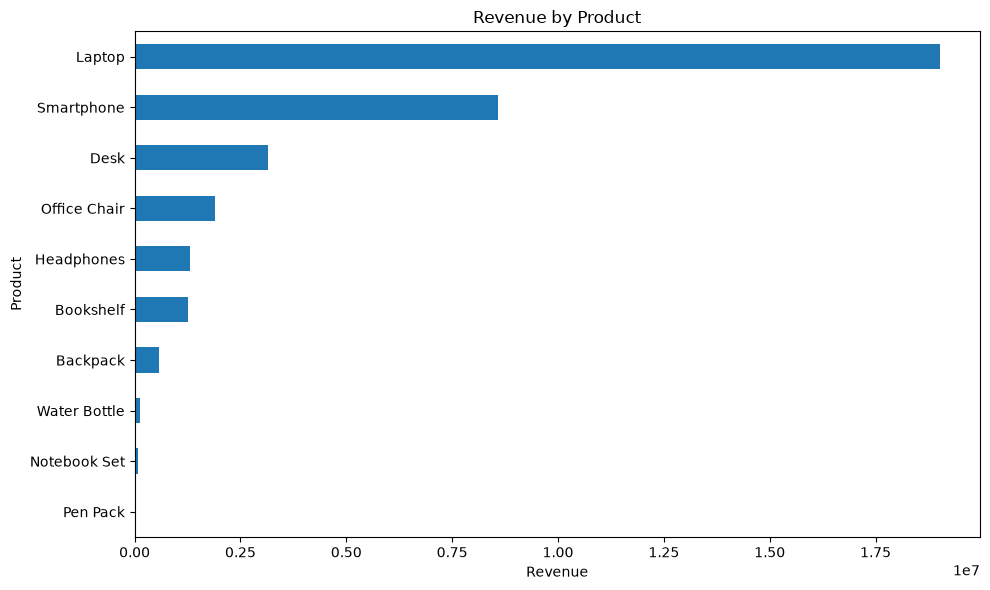

In [67]:
plt.figure(figsize=(10, 6))

product_sales.sort_values().plot(kind="barh")

plt.title("Revenue by Product")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

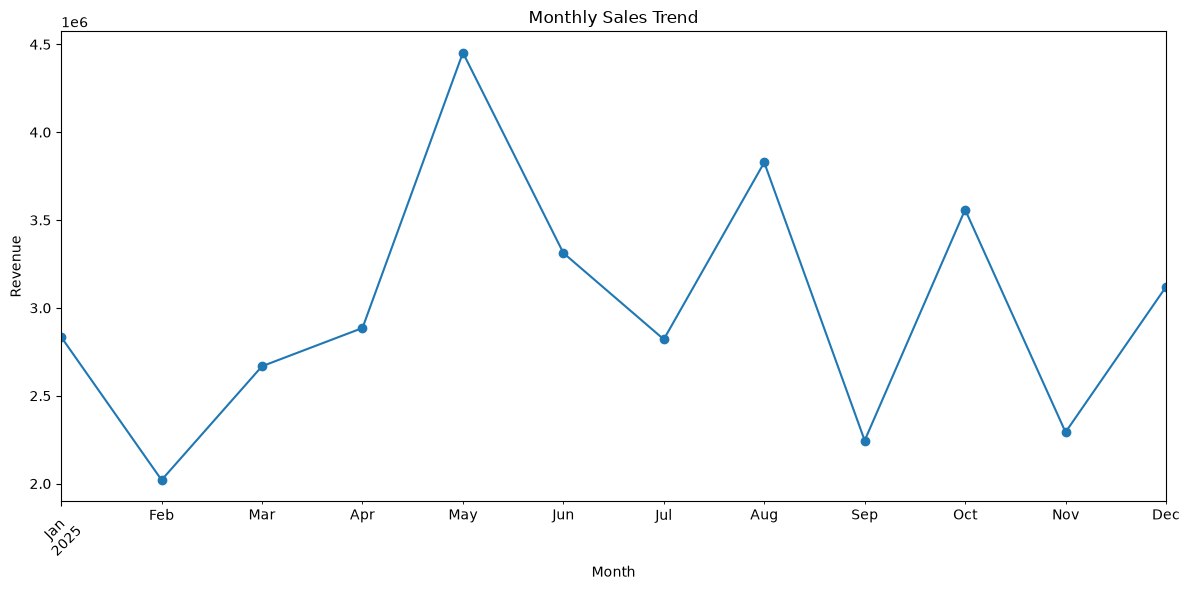

In [68]:
plt.figure(figsize=(12, 6))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

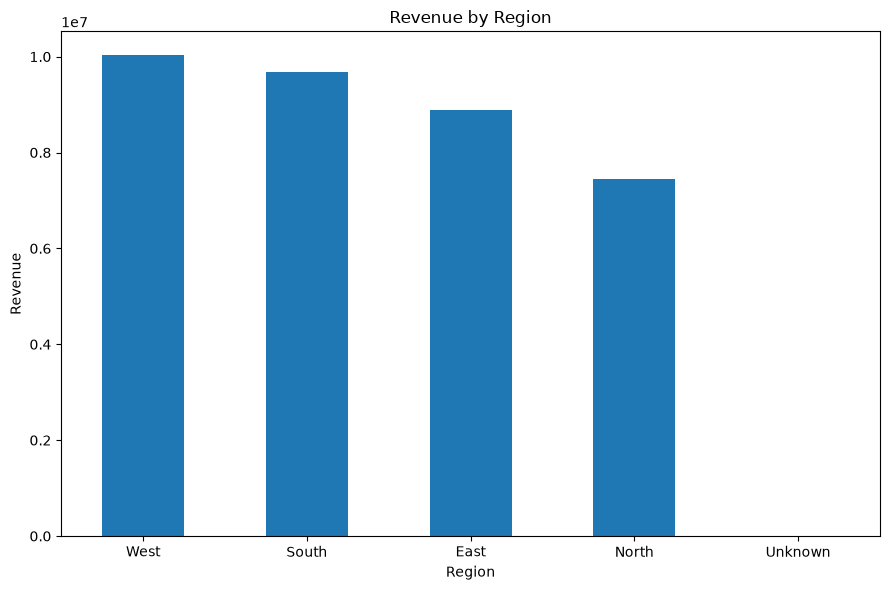

In [69]:
plt.figure(figsize=(9, 6))

region_sales.plot(kind="bar")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

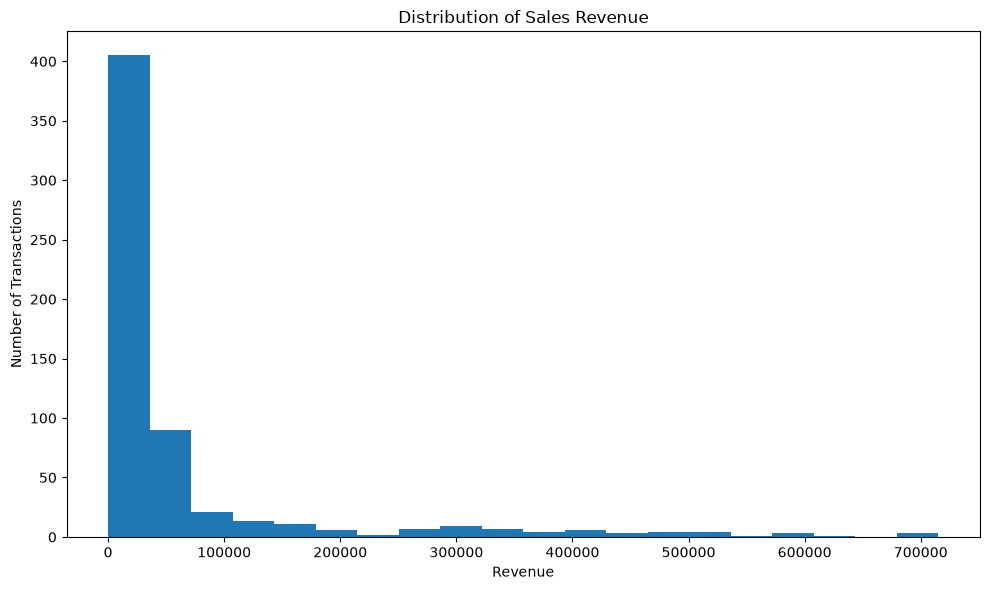

In [70]:
plt.figure(figsize=(10, 6))

plt.hist(df["Revenue"], bins=20)

plt.title("Distribution of Sales Revenue")
plt.xlabel("Revenue")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

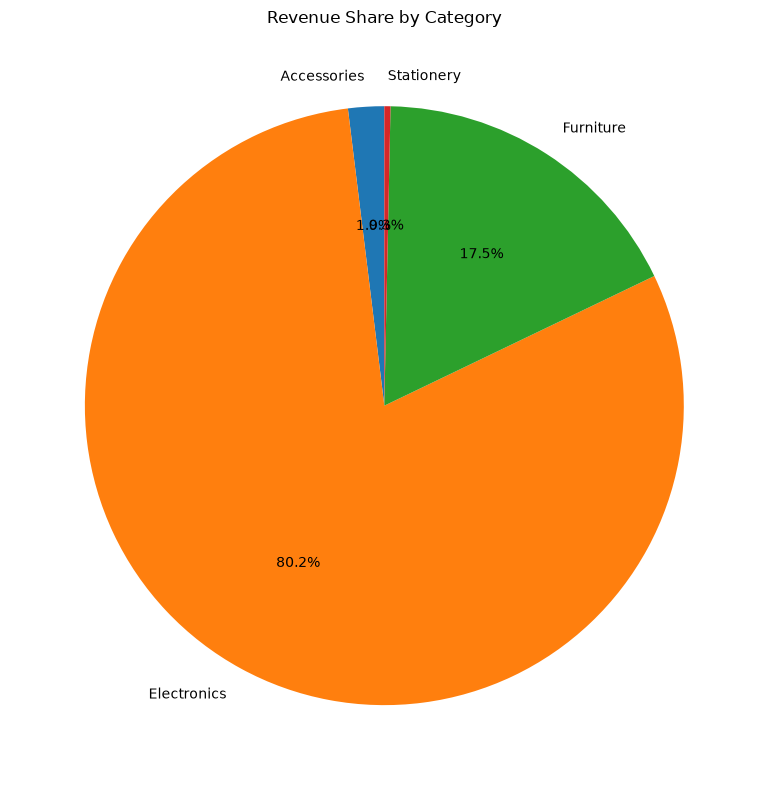

In [71]:
category_sales = df.groupby("Category")["Revenue"].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Share by Category")

plt.tight_layout()
plt.show()

## Key Findings

1. The highest-revenue product was Laptop.
2. The highest-revenue region was West.
3. The highest-revenue month was May 2025.
4. The total sales were ₹36,039,707.81.
5. There were 600 sales transactions after removing the duplicate.
6. The average order value was approximately ₹60,066.18.